# Agente DQN en Acrobot-v1

## Introducción

Este proyecto estudia el aprendizaje por refuerzo profundo aplicado a **Acrobot-v1**, un sistema de dos eslabones en el que el agente debe balancear el brazo hasta elevar el extremo libre por encima de la meta. En cada paso recibe una recompensa de `-1`, por lo que una recompensa total más cercana a cero representa una solución más rápida; `-500` indica que el episodio llegó al límite de tiempo sin alcanzar la meta.

Se entrena una red DQN durante 500 episodios. La primera gráfica muestra la recompensa obtenida en cada episodio y su media móvil de 20 episodios. Después, la política greedy se evalúa en 20 episodios con semillas fijas, y la segunda gráfica compara sus recompensas individuales con la media. La evaluación permite observar el desempeño del checkpoint fuera de las semillas usadas durante la selección periódica del modelo.


In [1]:
from pathlib import Path
import os
import sys

search_paths = [Path.cwd(), *Path.cwd().parents]
search_paths.append(Path.home() / "Sabana_DQN_Reinforced_Learning_run")
project_root = next(
    (path.resolve() for path in search_paths if (path / "train.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No encuentro train.py. Abre este notebook desde una copia local del repositorio."
    )

os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import train as dqn_train

print(f"Proyecto: {project_root}")
print(f"Episodios configurados: {dqn_train.EPISODES}")

Proyecto: C:\Users\PaolaEspinosaHurtado\Sabana_DQN_Reinforced_Learning_run
Episodios configurados: 500


## 1. Entrenamiento

Se ejecuta el entrenamient desde cero y se imprime el avance cada 10 episodios y se almacena el mejor checkpoint según sus evaluaciones periódicas.

In [2]:
dqn_train.main()

Episodio   10 | media entrenamiento (últ. 10):  -500.0 | eval greedy:  -500.0 | mejor:  -500.0 | epsilon: 0.68
Episodio   20 | media entrenamiento (últ. 10):  -370.2 | eval greedy:  -500.0 | mejor:  -500.0 | epsilon: 0.45
Episodio   30 | media entrenamiento (últ. 10):  -237.9 | eval greedy:  -431.8 | mejor:  -431.8 | epsilon: 0.30
Episodio   40 | media entrenamiento (últ. 10):  -179.3 | eval greedy:  -500.0 | mejor:  -431.8 | epsilon: 0.18
Episodio   50 | media entrenamiento (últ. 10):  -154.7 | eval greedy:   -96.0 | mejor:   -96.0 | epsilon: 0.08
Episodio   60 | media entrenamiento (últ. 10):  -182.9 | eval greedy:   -90.6 | mejor:   -90.6 | epsilon: 0.05
Episodio   70 | media entrenamiento (últ. 10):  -142.4 | eval greedy:  -500.0 | mejor:   -90.6 | epsilon: 0.05
Episodio   80 | media entrenamiento (últ. 10):  -151.6 | eval greedy:  -500.0 | mejor:   -90.6 | epsilon: 0.05
Episodio   90 | media entrenamiento (últ. 10):  -182.1 | eval greedy:  -500.0 | mejor:   -90.6 | epsilon: 0.05
E

## 2. Resultados del entrenamiento

El CSV contiene una recompensa por episodio; la media, el mejor episodio y la media de los últimos 20 ayudan a resumir el aprendizaje. La imagen se genera durante el entrenamiento.

### Figura 1. Recompensa durante el entrenamiento

- **Eje horizontal:** episodio de entrenamiento (1 a 500).
- **Eje vertical:** recompensa total del episodio. Al ser negativa, subir hacia cero significa que el agente resuelve la tarea en menos pasos.
- **Línea azul:** recompensa individual, que fluctúa de un episodio a otro.
- **Línea naranja:** media móvil de 20 episodios, que permite distinguir la tendencia general del ruido.

En esta corrida, la media móvil mejora claramente y termina alrededor de `-92` en los últimos 20 episodios; la media de los 500 episodios es `-135.71` y la mejor recompensa es `-61`. Persisten caídas puntuales, algunas hasta `-500`, señal de que la política todavía puede fallar o llegar al límite de tiempo durante el entrenamiento.

Episodios: 500
Recompensa media: -135.71
Mejor episodio: -61
Media de los últimos 20: -91.55


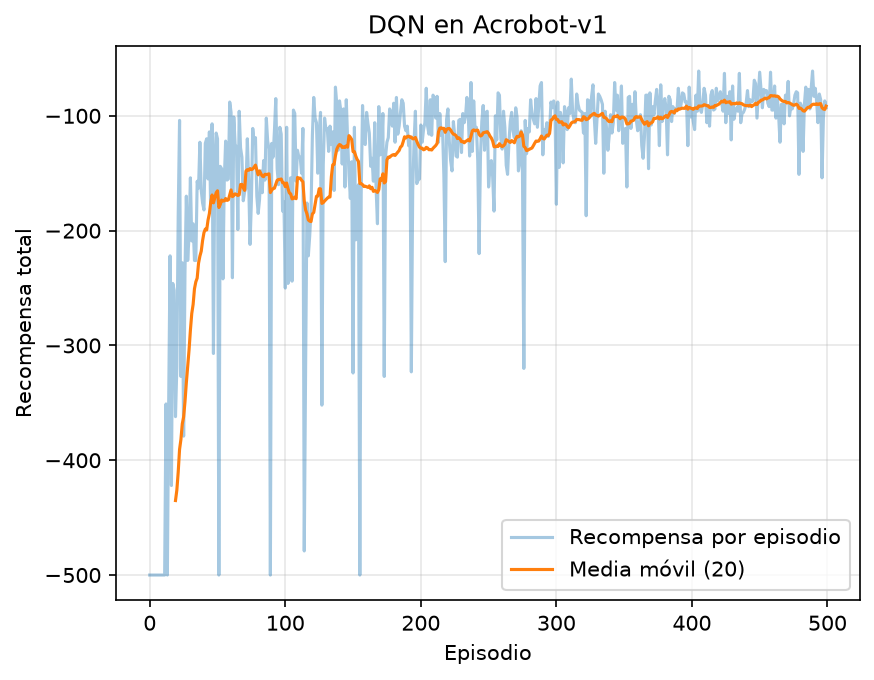

In [3]:
from IPython.display import Image, display

rewards = np.loadtxt("rewards.csv", delimiter=",", comments="#")
print(f"Episodios: {len(rewards)}")
print(f"Recompensa media: {rewards.mean():.2f}")
print(f"Mejor episodio: {rewards.max():.0f}")
print(f"Media de los últimos 20: {rewards[-20:].mean():.2f}")
display(Image(filename="training_curve.png"))

## 3. Evaluación del agente

El checkpoint se ejecuta sin exploración en 20 episodios con semillas fijas (1000 a 1019). La tabla impresa por la celda muestra la recompensa de cada episodio.

### Figura 2. Recompensas de evaluación

- **Eje horizontal:** episodio de evaluación.
- **Eje vertical:** recompensa total. Los puntos más altos (menos negativos) corresponden a episodios resueltos en menos pasos.
- **Línea azul con marcadores:** recompensa de cada uno de los 20 episodios.
- **Línea roja discontinua:** recompensa media de la evaluación.

El agente obtuvo `-73.8 ± 10.2`, con un rango de `-98` a `-61`. Ninguno de los 20 episodios terminó en `-500`, así que el agente alcanzó la meta antes del límite de tiempo en todos los casos. La desviación estándar y el rango muestran que la duración aún cambia según el estado inicial.

Episodio  1: -91
Episodio  2: -81
Episodio  3: -70
Episodio  4: -62
Episodio  5: -66
Episodio  6: -84
Episodio  7: -69
Episodio  8: -69
Episodio  9: -70
Episodio 10: -98
Episodio 11: -70
Episodio 12: -83
Episodio 13: -62
Episodio 14: -83
Episodio 15: -61
Episodio 16: -70
Episodio 17: -69
Episodio 18: -72
Episodio 19: -83
Episodio 20: -62

Media: -73.8 ± 10.2 (mín -98, máx -61)


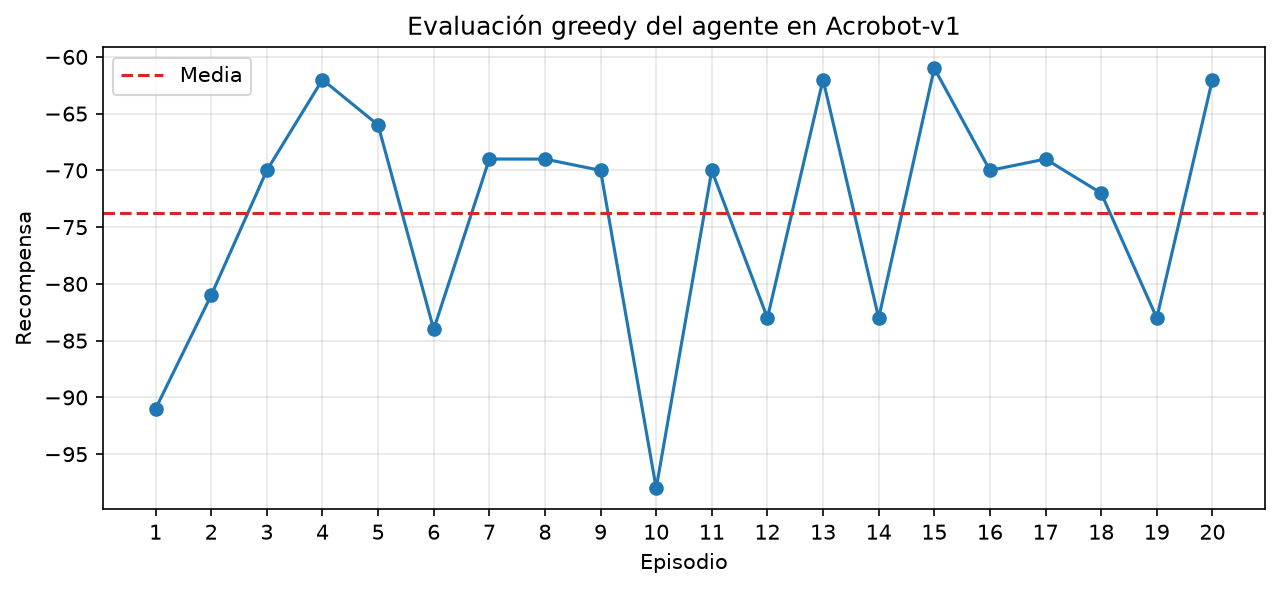

In [5]:
import gymnasium as gym
import torch
from IPython.display import Image, display
from train import ENV_ID, QNetwork

env = gym.make(ENV_ID)
q_net = QNetwork(env.observation_space.shape[0], env.action_space.n)
q_net.load_state_dict(torch.load("sabana_dqn_rl.pth", map_location="cpu", weights_only=True))
q_net.eval()

evaluation_rewards = []
for episode in range(20):
    state, _ = env.reset(seed=1000 + episode)
    total_reward = 0.0
    done = False
    while not done:
        with torch.no_grad():
            action = q_net(torch.tensor(state, dtype=torch.float32)).argmax().item()
        state, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        done = terminated or truncated
    evaluation_rewards.append(total_reward)
    print(f"Episodio {episode + 1:2d}: {total_reward:.0f}")
env.close()

evaluation_rewards = np.asarray(evaluation_rewards)
print(
    f"\nMedia: {evaluation_rewards.mean():.1f} ± {evaluation_rewards.std():.1f} "
    f"(mín {evaluation_rewards.min():.0f}, máx {evaluation_rewards.max():.0f})"
)

plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, len(evaluation_rewards) + 1), evaluation_rewards, marker="o")
plt.axhline(evaluation_rewards.mean(), color="tab:red", linestyle="--", label="Media")
plt.xlabel("Episodio")
plt.ylabel("Recompensa")
plt.title("Evaluación greedy del agente en Acrobot-v1")
plt.xticks(np.arange(1, len(evaluation_rewards) + 1, 1))
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("evaluation_curve.png", dpi=150, bbox_inches="tight")
display(Image(filename="evaluation_curve.png"))
plt.close()

## Reflexiones sobre los resultados

La tendencia de la recompensa durante el entrenamiento muestra que el agente sí aprendió una política útil: la media móvil pasó de valores cercanos a `-500` al inicio a alrededor de `-92` al final. En Acrobot-v1 cada paso resta un punto, así que la evaluación final (`-73.8` en promedio) equivale aproximadamente a alcanzar la meta en 74 pasos. Además, los 20 episodios de evaluación terminaron antes del límite de tiempo. Esto es una señal alentadora, aunque no significa que el agente haya encontrado una solución perfecta: todavía necesitó varios pasos para completar la tarea.

También es importante no interpretar la curva como un aprendizaje uniforme. Las recompensas individuales presentan fluctuaciones y durante el entrenamiento hubo episodios de `-500`; la política todavía podía fallar mientras exploraba. En cambio, la evaluación greedy se hizo sin acciones aleatorias y no tuvo episodios de ese tipo. La diferencia entre ambos resultados muestra por qué conviene analizar tanto la curva de entrenamiento como una evaluación separada. Como solo se ejecutó una corrida y se evaluaron 20 semillas, estos datos describen este experimento, pero no bastan para asegurar que el rendimiento se mantenga en todas las condiciones.

## Lo que más costó

Uno de los mayores retos fue lograr que el aprendizaje fuera suficientemente estable. DQN combina varios elementos que deben trabajar juntos: la exploración mediante `epsilon-greedy`, la memoria de experiencias y la red objetivo. Si el agente explora demasiado, tarda en aprovechar lo aprendido; si deja de explorar muy pronto, puede quedarse con una estrategia poco eficaz. Las variaciones de la curva y las evaluaciones periódicas que a veces caían hasta `-500` hicieron necesario mirar más allá de un episodio aislado.

Otro reto fue decidir cómo medir y conservar el resultado. El último modelo entrenado no necesariamente es el mejor, por lo que se guardó el checkpoint con mejor evaluación greedy y luego se probó en semillas distintas. Esta separación ayudó a comprobar el desempeño con menos ruido de exploración y a no basar la conclusión únicamente en la recompensa de entrenamiento.

## Conclusiones

Los resultados permiten observar qué aprendió el agente y también los límites de esta prueba:

1. **El agente resolvió los 20 episodios de evaluación.** Obtuvo una recompensa media de `-73.8`. Como recibe `-1` por cada paso, este valor equivale aproximadamente a alcanzar la meta en 74 pasos; una recompensa más cercana a cero significa que necesitó menos pasos.
2. **Durante el entrenamiento se aprecia una mejora, aunque con altibajos.** La media de los últimos 20 episodios (`-91.55`) es mejor que la media de los 500 (`-135.71`). Sin embargo, las caídas, algunas hasta `-500`, muestran que el agente no aprende de forma constante y que en ocasiones no alcanza la meta dentro del límite de tiempo.
3. **En esta evaluación, los resultados fueron parecidos, pero no idénticos.** Las recompensas estuvieron entre `-98` y `-61`, con una desviación estándar de `10.2`. Esto indica que el agente tardó distinto número de pasos según las condiciones iniciales.
4. **Se evaluó el mejor checkpoint guardado durante el entrenamiento.** El programa compara periódicamente la política y conserva el modelo con mejor resultado en esas comprobaciones; por eso, el checkpoint no tiene que corresponder al último episodio.
5. **La conclusión aplica a esta corrida y a estas 20 pruebas.** Los resultados son alentadores, pero no garantizan el mismo desempeño en todas las condiciones. Para comprobarlo mejor, se puede repetir el entrenamiento con distintas semillas y evaluar más episodios.

En conjunto, la corrida muestra que DQN puede aprender a resolver Acrobot con menos pasos, aunque su aprendizaje presenta variaciones. La evaluación amplia lo que observamos durante el entrenamiento, pero harían falta más corridas para saber qué tan estable es el resultado.